In [18]:
import matplotlib.pyplot as plt
import pandas as pd

In [3]:
df = pd.read_csv("application_email_counts.csv")
df.head()


,Date,Count
0,2020-07-29,1
1,2020-08-26,2
2,2021-10-10,1
3,2021-11-23,1
4,2021-11-30,1


In [4]:
df = df.assign(Date=pd.to_datetime(df["Date"]))
df.dtypes

Date     datetime64[us]
Count             int64
dtype: object

In [5]:
df = df[df["Date"] >= "2025-01-01"]
df.head()

,Date,Count
384,2025-01-09,1
385,2025-01-24,1
386,2025-01-28,1
387,2025-02-21,1
388,2025-03-02,1


In [6]:
df["year"] = df["Date"].dt.year

In [7]:
df.groupby("year")["Count"].sum().reset_index()

,year,Count
0,2025,416
1,2026,160


In [8]:
df.head()

,Date,Count,year
384,2025-01-09,1,2025
385,2025-01-24,1,2025
386,2025-01-28,1,2025
387,2025-02-21,1,2025
388,2025-03-02,1,2025


Mon    1.31
Tue    0.89
Wed    1.08
Thu    1.08
Fri    0.71
Sat    0.58
Sun    0.39
Name: Count, dtype: float64

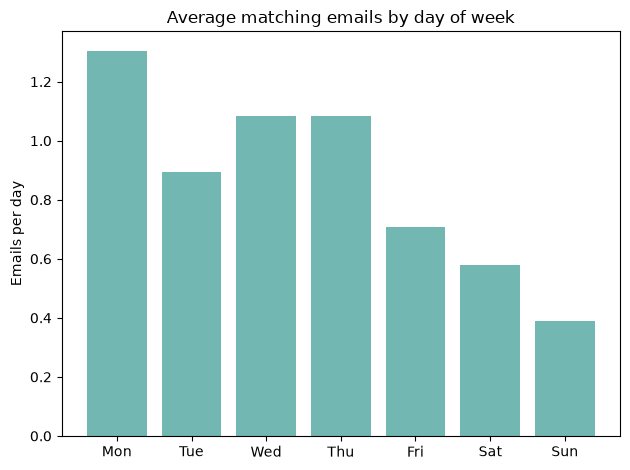

In [24]:
daily = (
    df.set_index("Date")["Count"]
    .asfreq("D", fill_value=0)
)

weekday_avg = (
    daily.groupby(daily.index.dayofweek).mean()
    .reindex(range(7))
)
weekday_avg.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

fig, ax = plt.subplots()
ax.bar(weekday_avg.index, weekday_avg.values, color="#72B7B2")
ax.set_title("Average matching emails by day of week")
ax.set_ylabel("Emails per day")
fig.tight_layout()


weekday_avg.round(2)

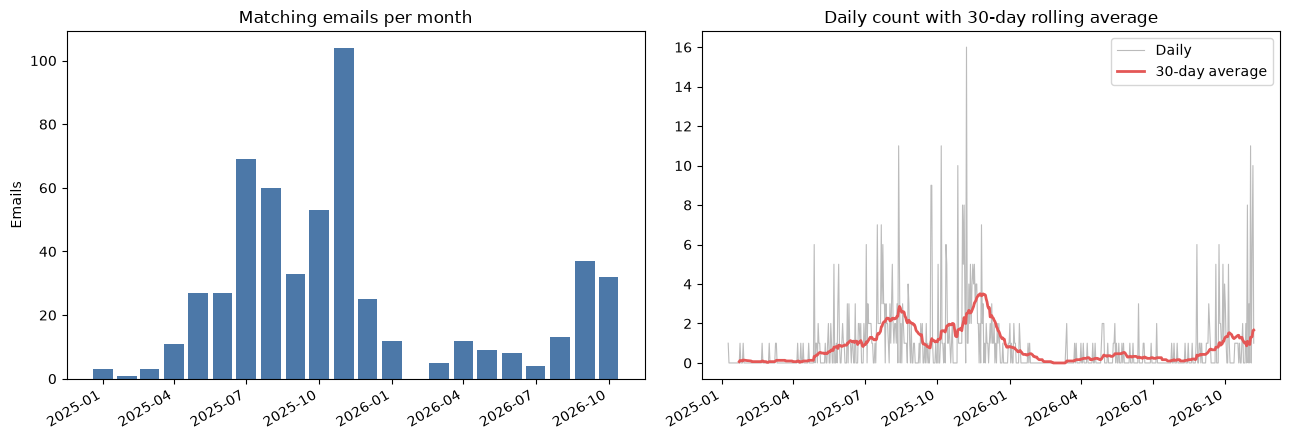

In [ ]:
last_day = daily.index.max()
monthly = daily.resample("MS").sum()
if last_day != last_day +pd.offsets.MonthEnd(0):
    monthly = monthly.iloc[:-1]

rolling_30 = daily.rolling(30, min_periods=15).mean()

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

ax[0].bar(monthly.index, monthly.values, width=25, color="#4C78A8")
ax[0].set_title("Matching emails per month")
ax[0].set_ylabel("Emails")

ax[1].plot(daily.index, daily.values, color="#BBBBBB", linewidth=0.8, label="Daily")
ax[1].plot(rolling_30.index, rolling_30.values, color="#E45756", linewidth=2, label="30-day average")
ax[1].set_title("Daily count with 30-day rolling average")
ax[1].legend()

fig.autofmt_xdate()
fig.tight_layout()

In [ ]:
median = daily.median()
mad = (daily - median).abs().median()

if mad == 0:
    mad = (daily - median).abs().mean()

robust_z = 0.6745 * (daily - median) / mad
spikes = daily[robust_z > 3.5]

print(f"{len(spikes)} spike days flagged (robust z > 3.5)")
spikes.sort_values(ascending=False).head(10).to_frame("Count")

34 spike days flagged (robust z > 3.5)


,Count
Date,
2025-11-07,16
2025-08-13,11
2026-11-02,11
2025-10-06,11
2025-10-27,10
2026-11-05,10
2025-09-23,9
2025-09-24,9
2025-11-04,8


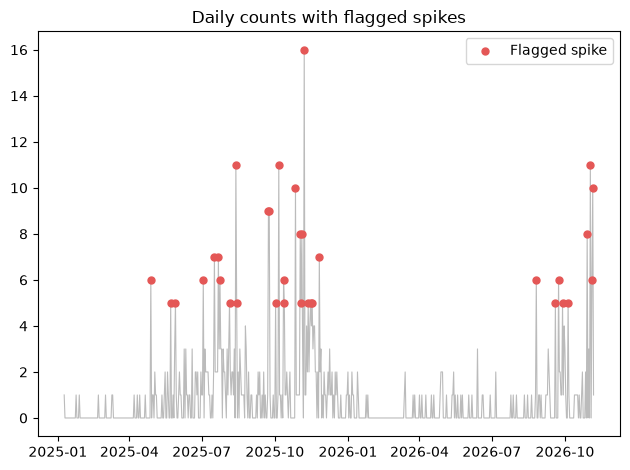

In [27]:
fig, ax = plt.subplots()
ax.plot(daily.index, daily.values, color="#BBBBBB", linewidth=0.8)
ax.scatter(spikes.index, spikes.values, color="#E45756", s=25, zorder=3, label="Flagged spike")
ax.set_title("Daily counts with flagged spikes")
ax.legend()
fig.tight_layout()
